# 342. Does a pattern label from Swiss-Prot predict what an alternative exon does?

An alternative exon adds or removes 10 to 150 residues from a protein. Four kinds of label can
say what that stretch does, from most to least settled:

1. **Folded-domain overlap.** The exon's residues sit inside a Pfam domain.
2. **Short motifs and modification sites.** An ELM motif, or a UniProt modified residue
   (MOD_RES), inside the exon.
3. **Composition and pattern class.** Disorder (IUPred), κ (how evenly positive and negative
   residues are mixed: 0 when they alternate, 1 when they sit apart), Ω_aro (the same measure for
   aromatic residues against all others), net charge, the share of each residue class, and
   low-complexity stretches.
4. **Pattern label transferred from a database.** The exon's residues share an exact k-mer, in a
   reduced alphabet, with an annotated region of another protein (a Swiss-Prot REGION, COMPBIAS,
   MOTIF, REPEAT, ZN_FING, COILED or DOMAIN feature). kmerseek finds these.

Kinds 1 to 3 need no search. Only kind 4 needs a k-mer index.

**Question.** Does the kind 4 label predict whether neurons include or skip an exon more than
progenitors do, beyond what kinds 1 to 3 already predict?

**What this decides.** If it does not, kmerseek has no role in exon annotation, and exon function
is kinds 1 to 3 plus Exon Ontology. If it does, the next notebook adds a second outcome (TDP-43
loss in motor neurons, Tanaka et al. 2025) and a second index (PhaSePro and DisProt regions).

### Prior work

Tranchevent, Léon-Charles, Fabien Aubé, Louis Dulaurier, et al. "Identification of Protein
Features Encoded by Alternative Exons Using Exon Ontology." *Genome Research* 27, no. 6 (2017):
1087–97. https://doi.org/10.1101/gr.212696.116.

**Note.** Exon Ontology already labels exons with kinds 1 to 3. This notebook does not rebuild it.
It adds kind 4 and tests it.

Buljan, Marija, Guilhem Chalancon, Sebastian Eustermann, et al. "Tissue-Specific Splicing of
Disordered Segments That Embed Binding Motifs Rewires Protein Interaction Networks." *Molecular
Cell* 46, no. 6 (2012): 871–83. https://doi.org/10.1016/j.molcel.2012.05.039.

**Note.** Tissue-specific exons code for disordered segments rich in modification sites and
binding motifs. This is the positive control (rule 2 below).

### The example exon: ZNF207 (BuGZ) exon 9

chr17:32,366,665–32,366,757 (GRCh38, Ensembl 116), residues 277–307 of ZNF207-203, 93 nt, starts
in phase 0, keeps the reading frame:

```
MGTPVTSSSTASSNSESLSASSKALFPSTAQ
```

11 serines of 31 residues, 1 aromatic residue (F302), 2 charged residues, IUPred mean 0.78
(IUPred run on the whole isoform, averaged over the exon), pI 5.8. In `aro_hyd_chg_pol4`, 20 of its
31 residues are polar (`s`) and 8 are other hydrophobic (`a`). Section 0 prints it in every alphabet searched, so the reader can see
which alphabets have anything to match. The alphabets were not chosen from this exon.

In set A ([notebook 341](https://github.com/seanome/2024-kmerseek-analysis/blob/olgabot/condensate-exons-341/notebooks/341_condensate_exons_aro_hyd_chg_pol4_bugz.ipynb),
section 3b), neurons include it more in all three donors. Ψ is 0.95 in the germinal zone against
0.99 in the cortical plate, then 0.91 against 0.97, then 0.91 against 0.97. Each of those
changes is under 0.10, so under the outcome rule below it is in no class and is left out of the
test. Section 1 prints its class.

### Data

| what | source | version and check |
|---|---|---|
| Set A isoforms and read counts | Patowary et al. 2024, Dryad doi:10.5061/dryad.0rxwdbs68: Data S1 (`Bulk.gtf`, GRCh37) and Data S2 sheet B (counts per isoform, 3 donors × 4 replicates in each of germinal zone and cortical plate) | downloaded 2026-10-14; SHA-256 printed in section 0 |
| Genome for the isoform proteins | GENCODE release 33, GRCh37 primary assembly | md5 c9f86b6083dd05b9799eca02c79f651d |
| Exon event table | `scripts/build_341_exon_table.py` (notebook 341, [PR 140](https://github.com/seanome/2024-kmerseek-analysis/pull/140)), run on Sherlock as Slurm job 47934291, 2026-10-15: 12 min, 2.5 GB peak | md5 printed in section 0 |
| Regions index | [PR 114](https://github.com/seanome/2024-kmerseek-analysis/pull/114): Swiss-Prot 2026_03 minus Mammalia, every annotated feature cut out with flanks, rebuilt at k_max 22 on 2026-10-13 (640_927 entries, 46_921_644 target residues, 10-residue decoy windows, decoy md5 1dd147349181efd1df7f3990b0883d5f) | to be checked in Stop 3 |
| Query decoys | `dipeptide_shuffle` in `nextflow-runs/shared/decoys.py` ([PR 138](https://github.com/seanome/2024-kmerseek-analysis/pull/138)) | imported in Stop 3 |
| Copy rate κ and penalty C for the two new alphabets | `scripts/342_kappa_new_alphabets.py` on notebook 230's Pfam-A 38.2 seed pairs, then `tools/kappa-for-alphabet` from olgabot/dark-set-kmerseek-0.4 (ec91da5) | printed in section 0 |

The prompt for this notebook gave the regions index as 639_854 entries. That is the k_max 21
build. The k_max 22 rebuild has 640_927 entries; Stop 3 uses the k_max 22 build and prints its
entry count.

### What had been seen before these rules were written

From notebook 341 (PR 140): the event table has 30_548 one-exon events in 8_890 genes. 7_500 of
them keep the frame with the exon inside the ORF, and 7_062 of those have proteins that differ
only by the exon. Under notebook 341's own rule (at least 10 reads per donor and region, all
three donors in the same direction, mean change at least 0.1), 658 exons change: 431 included
more in neurons and 227 less. The ZNF207 exon 9 numbers above were also seen. No count under the
rule below, no unchanged-class count, and no label of any kind on any exon except ZNF207 exon 9
had been seen.

### Rule 1: the outcome per exon

* Ψ (percent spliced in) per donor per region = reads of including isoforms / (reads of including
  plus skipping isoforms), each summed over the four replicates.
* ΔΨ = Ψ(cortical plate) − Ψ(germinal zone), per donor. The cortical plate holds neurons, the
  germinal zone holds progenitors.
* **Included more in neurons**: ΔΨ > +0.10 in all three donors.
* **Skipped more in neurons**: ΔΨ < −0.10 in all three donors.
* **Unchanged**: |ΔΨ| < 0.05 in all three donors.
* Any other exon is left out of the test and counted in the funnel.
* Only events with at least 20 reads (including plus skipping) in both regions in every donor.
* Only events whose two proteins are the same apart from the exon (`orf_otherwise_identical`),
  whose exon keeps the frame, and whose exon codes for 10 to 150 residues.

### Rule 2: tune and test halves

Genes, not exons, are split in half at random (numpy seed 342) before any label is computed. All
exons of a gene go to the same half. Every choice (the C value of the model, the decoy cutoff of
each kmerseek setting) is made on the tune half. The test half is read once, at the end.

### Rule 3: the positive control (Buljan et al. 2012)

On the tune half, exons in the two changed classes, pooled, have a higher mean IUPred score than
unchanged exons. The statistic is the difference of the two class means (changed minus
unchanged), with a 95% interval from 10_000 bootstrap resamples of genes. It holds if the whole
interval is above 0. If it fails, the notebook stops: the exon table or the outcome rule is wrong.

### Rule 4: the kill test

On the test half, a logistic regression tells "included more in neurons" from "unchanged".
Model 3 uses the kind 1 to 3 features. Model 4 uses the same features plus the kind 4 features.
Both are fit on the tune half (standardized features, L2 penalty, its strength chosen by 5-fold
cross-validation with folds split by gene) and then scored once on the test half.

* The statistic is the AUROC gain, model 4 minus model 3, on the test half, with a 95% interval
  from 10_000 bootstrap resamples of test genes. AUROC is the chance that a random exon of the
  changed class gets a higher score than a random unchanged exon: 0.5 is no signal, higher is
  better.
* **PASS** if the whole interval is at or above 0.02.
* **KILL** if the whole interval is below 0.02.
* **Unclear** if the interval contains 0.02. The notebook then gives the number of test exons
  that would make the interval narrow enough to decide, and says whether set A has that many.
* The same test is run for "skipped more in neurons" against "unchanged". Each comparison gets its
  own verdict. kmerseek has a role in exon annotation if at least one comparison passes. It has
  none if both are KILL. Any other pair of verdicts is unclear.
* A missing feature value (Ω_aro on an exon with 10% or fewer aromatic residues; no kind 4 hit) is
  set to 0 and gets its own 0/1 column saying it was missing.
* Power: with fewer than 100 exons of a changed class on the tune half, the test is unlikely to
  resolve a gain of 0.02. Section 1 says so if that happens.

### Predictions, written now

* **P1.** The positive control holds: changed exons have a higher mean IUPred score than unchanged
  ones, and the 95% interval of the difference is above 0.
* **P2.** Fewer than 30% of exons get any kind 4 hit at E < 1 (a hit, in any of the four kmerseek
  settings, on a real Swiss-Prot entry, whose query coordinates overlap at least one exon
  residue). The exon queries are short, so they carry few k-mers.
* **P3.** The kind 4 score is mostly explained by kind 3 features: Spearman |ρ| above 0.5 between
  −log10(best E) and at least one of IUPred mean, other-hydrophobic fraction (AILMV) or
  low-complexity fraction, over exons with a hit. The expected one is the low-complexity fraction.
* **P4.** KILL. Model 4 adds less than 0.02 AUROC in both comparisons. The notebook is built so
  that this prediction can fail.

### kmerseek settings

A kmerseek setting is one alphabet, k-mer size k, scaled, extension penalty and mask. All four use
scaled 1, mask off, extension with the alphabet's own mismatch penalty C, and X-drop 4 × C (the
dark-set run's rule). The other search options are PR 114's (`--threshold 0.0
--min-shared-kmers 2 --max-query-pvalue 0.05 --min-region-score 1.3 --chain-max-gap 30
--chain-max-shift 10`).

| alphabet | classes | k | penalty C | X-drop | source of C |
|---|---|---|---|---|---|
| aro_hyd_chg_pol4 | FWY, AILMV, DEKR, SNQTGCPH | 11 | 0.58 | 2.32 | computed here (section 0) |
| aro_hyd_arg_chg_pol5 | FWY, AILMV, R, DEK, SNQTGCPH | 9 | 0.46 | 1.85 | computed here (section 0) |
| hp_pbotc_1st_ed2 | ACFILMPVWY, DEGHKNQRST | 21 | 1.59 | 6.35 | dark-set table |
| protein20 | the 20 amino acids | 5 | 0.14 | 0.57 | dark-set table |

The last two are PR 114's settings 2 and 4, so their behaviour on this index is known. C comes
from the copy rate κ, the chance-corrected share of aligned Pfam seed pairs (20–30% identity) that
put the two residues in the same class: C = −ln(1 − κ) / ln(1 + κ·n − κ) for an alphabet of n
classes. That formula assumes the classes are equally common. They are not in
`aro_hyd_chg_pol4` (FWY is about 8% of residues), the same as for every row of the dark-set table.

E-values use the Karlin-Altschul fit of the whole-protein index (kmerseek's `--ka-r-database`
route, seanome/kmerseek PR 144), as PR 114 did, because the regions index's own fit changed its
slope up to tenfold between two decoy windows of the same setting. The two new alphabets have no
whole-protein index yet, so Stop 3 builds one for the fit.

The kmerseek build must hold the two new alphabets (seanome/kmerseek PR 146) and the equal-k-mer-set
fix (seanome/kmerseek PR 141). Both PRs were open on 2026-10-16. Stop 3 records the commit and the
image digest.

**Own-gene hits.** Index entries from the query's own gene (same gene symbol in UniProt's gene
name field) are removed before kind 4 features are computed. Mammals are already out of the
index, so what this removes is the same gene in other animals. The section that asks how much of
the kind 4 signal is a self-hit counts those removed hits.

### Order of work

* Stop 0, this cell and section 0: committed before any count is read.
* Stop 1: the exon table, the outcome classes and the halves (section 1).
* Stop 2: kinds 1 to 3, the positive control, the alphabet check.
* Stop 3: kind 4 on Sherlock.
* Stop 4: the test.

In [1]:
import hashlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

sys.path.insert(0, str(Path.cwd()))
import condensate_exon_utils as cu
import pubfig as pf

pf.use_style()
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_width_chars(160)

REPO = Path.cwd().parent
DATA_341 = REPO / "data" / "341_condensate_exons"
DRYAD = Path("/Users/olga/data/condensate_exons_341/patowary2024_dryad")
TABLES = REPO / "tables" / "342"
FIGURES = REPO / "figures" / "342"
FIGURES.mkdir(parents=True, exist_ok=True)

#: Seed for the gene split and every bootstrap (rule 2).
SEED = 342


def save_figure(fig, stem):
    # pf.save, then the PNG as an 8-bit palette of at most 256 colours. pf.save does the
    # palette step itself once PR 123 is merged; until then it is done here.
    pf.save(fig, stem)
    if not hasattr(pf, "to_256_colours"):
        from PIL import Image

        png = Path(stem).with_suffix(".png")
        Image.open(png).convert("RGB").quantize(
            colors=256, dither=Image.Dither.NONE
        ).save(png, optimize=True)

## 0. Inputs, the example exon and the kmerseek settings

Checksums of the inputs, the κ rows behind the two new penalties, and ZNF207 exon 9 in every
alphabet searched.

In [2]:
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def md5(path):
    return hashlib.md5(Path(path).read_bytes()).hexdigest()


# SHA-256 values listed by Dryad for doi:10.5061/dryad.0rxwdbs68 (also in notebooks/341_exon_table_setA.sbatch).
DRYAD_SHA256 = {
    "DataS1.tar.gz": "7bffff510a453a2bff7f6683bdad0140b3e5ca4e31ecda5b0ecefad498807eab",
    "DataS2.xlsx.zip": "43230bda4631add5e4257c70ef239ad6f1e57598ac8e6d042dcb5de8ccecf19f",
}
rows = []
for name, expected in DRYAD_SHA256.items():
    got = sha256(DRYAD / name)
    assert got == expected, name
    rows.append(
        {"file": f"Dryad {name}", "checksum": f"sha256 {got}", "matches source": True}
    )
EVENTS_PATH = DATA_341 / "341_setA_exon_events.parquet"
rows.append(
    {
        "file": EVENTS_PATH.name,
        "checksum": f"md5 {md5(EVENTS_PATH)}",
        "matches source": None,
    }
)
for path in sorted(TABLES.glob("*kappa*")):
    rows.append(
        {
            "file": f"tables/342/{path.name}",
            "checksum": f"md5 {md5(path)}",
            "matches source": None,
        }
    )
pl.DataFrame(rows)

file,checksum,matches source
str,str,bool
"""Dryad DataS1.tar.gz""","""sha256 7bffff510a453a2bff7f668…",true
"""Dryad DataS2.xlsx.zip""","""sha256 43230bda4631add5e4257c7…",true
"""341_setA_exon_events.parquet""","""md5 247350bb1b270f9eb0585cb457…",null
"""tables/342/230_pair_kappa_new_…","""md5 7b5ef6de45d65b41168c7e4964…",null
"""tables/342/dark_set_kappa_by_a…","""md5 d0774e68fbf8aa38cc4c2bfbfe…",null
"""tables/342/kappa_by_alphabet_n…","""md5 257f3dafbc7b54f6f07d9c89a9…",null


In [3]:
# kappa and C: the two new alphabets from scripts/342_kappa_new_alphabets.py, polarity4 recomputed
# by the same script as a check, and the two reused alphabets from the dark-set table (ec91da5).
new_rows = pl.read_csv(TABLES / "kappa_by_alphabet_new_rows.tsv", separator="\t")
dark_set = pl.read_csv(
    TABLES / "dark_set_kappa_by_alphabet.ec91da5.tsv",
    separator="\t",
    comment_prefix="#",
)
check = new_rows.filter(pl.col("alphabet") == "polarity4").drop("alphabet").row(0)
assert check == dark_set.filter(pl.col("alphabet") == "polarity4").drop("alphabet").row(
    0
)
print("polarity4 recomputed here equals the dark-set row:", check)

SETTINGS = pl.DataFrame(
    {
        "alphabet": [
            "aro_hyd_chg_pol4",
            "aro_hyd_arg_chg_pol5",
            "hp_pbotc_1st_ed2",
            "protein20",
        ],
        "k": [11, 9, 21, 5],
    }
).join(
    pl.concat([new_rows.filter(pl.col("alphabet") != "polarity4"), dark_set]),
    on="alphabet",
    how="left",
    maintain_order="left",
)
SETTINGS.select(
    "alphabet",
    "classes",
    "k",
    "kappa",
    "kappa_lo",
    "kappa_hi",
    "n_pairs",
    "c_opt",
    "xdrop_4c",
)

polarity4 recomputed here equals the dark-set row: (4, 0.2837, 0.2831, 0.2844, 37085, 0.54, 2.17)


alphabet,classes,k,kappa,kappa_lo,kappa_hi,n_pairs,c_opt,xdrop_4c
str,i64,i64,f64,f64,f64,i64,f64,f64
"""aro_hyd_chg_pol4""",4,11,0.3288,0.3281,0.3294,37085,0.58,2.32
"""aro_hyd_arg_chg_pol5""",5,9,0.3126,0.312,0.3132,37085,0.46,1.85
"""hp_pbotc_1st_ed2""",2,21,0.4389,0.438,0.4399,37085,1.59,6.35
"""protein20""",20,5,0.1988,0.1985,0.1992,37085,0.14,0.57


In [4]:
#: Class letters for printing. A class of aro_hyd_chg_pol4 or aro_hyd_arg_chg_pol5 is written as the
#: first residue of its cluster, lowercased, as kmerseek's build_reduced does (seanome/kmerseek PR 146, src/rust/alphabets.rs).
ALPHABET_CLUSTERS = {
    "protein20": list("ACDEFGHIKLMNPQRSTVWY"),
    "aro_hyd_chg_pol4": ["FWY", "AILMV", "DEKR", "SNQTGCPH"],
    "aro_hyd_arg_chg_pol5": ["FWY", "AILMV", "R", "DEK", "SNQTGCPH"],
    "hp_pbotc_1st_ed2": ["ACFILMPVWY", "DEGHKNQRST"],
}
LETTER_TABLES = {
    name: {aa: cl[0].lower() for cl in clusters for aa in cl}
    for name, clusters in ALPHABET_CLUSTERS.items()
}
LETTER_TABLES["protein20"] = {aa: aa for aa in ALPHABET_CLUSTERS["protein20"]}
# hp_pbotc_1st_ed2 is written h (hydrophobic) and p (polar), as in notebook 341.
LETTER_TABLES["hp_pbotc_1st_ed2"] = cu.HP_PBOTC_1ST_ED2
assert LETTER_TABLES["aro_hyd_chg_pol4"] == cu.ARO_HYD_CHG_POL4

HERO_GENE, HERO_ISOFORM = "ZNF207", "ZNF207-203"
HERO_FIRST = 277  # 1-based, inclusive, on ZNF207-203
HERO_LAST = 307
HERO_RESIDUES = "MGTPVTSSSTASSNSESLSASSKALFPSTAQ"
hero_protein = (DATA_341 / "ensembl_protein_ZNF207-203.txt").read_text().strip()
assert hero_protein[HERO_FIRST - 1 : HERO_LAST] == HERO_RESIDUES

print(
    f"{HERO_ISOFORM} residues {HERO_FIRST}-{HERO_LAST} (exon 9), Ensembl 116 translation\n"
)
for name, table in LETTER_TABLES.items():
    print(f"{name:>22}  {HERO_FIRST}  {cu.encode(HERO_RESIDUES, table)}  {HERO_LAST}")
print()
print(
    "aro_hyd_chg_pol4: "
    + ", ".join(
        f"{cl[0].lower()} = {cl}" for cl in ALPHABET_CLUSTERS["aro_hyd_chg_pol4"]
    )
)
print(
    "aro_hyd_arg_chg_pol5: "
    + ", ".join(
        f"{cl[0].lower()} = {cl}" for cl in ALPHABET_CLUSTERS["aro_hyd_arg_chg_pol5"]
    )
)
print("hp_pbotc_1st_ed2: h = ACFILMPVWY, p = DEGHKNQRST")
print(
    "The exon has no R, so aro_hyd_chg_pol4 and aro_hyd_arg_chg_pol5 write it the same way."
)

pol4 = cu.encode(HERO_RESIDUES, cu.ARO_HYD_CHG_POL4)
hero_stats = {
    "length (aa)": len(HERO_RESIDUES),
    "serines": HERO_RESIDUES.count("S"),
    "aromatic (FWY)": cu.aromatic_count(HERO_RESIDUES),
    "aromatic positions": [
        HERO_FIRST + i for i, aa in enumerate(HERO_RESIDUES) if aa in cu.AROMATIC
    ],
    "charged (DEKR)": sum(aa in "DEKR" for aa in HERO_RESIDUES),
    "polar class s in aro_hyd_chg_pol4": pol4.count("s"),
    "other hydrophobic class a in aro_hyd_chg_pol4": pol4.count("a"),
    "IUPred long mean, in the whole isoform": round(
        cu.iupred_mean_in_context(hero_protein, HERO_FIRST, HERO_LAST), 2
    ),
    "pI": round(cu.isoelectric_point(HERO_RESIDUES), 1),
    "isoform length (aa)": len(hero_protein),
}
print()
for key, value in hero_stats.items():
    print(f"{key:>40}: {value}")

ZNF207-203 residues 277-307 (exon 9), Ensembl 116 translation

             protein20  277  MGTPVTSSSTASSNSESLSASSKALFPSTAQ  307
      aro_hyd_chg_pol4  277  asssasssssassssdsasassdaafsssas  307
  aro_hyd_arg_chg_pol5  277  asssasssssassssdsasassdaafsssas  307
      hp_pbotc_1st_ed2  277  hpphhppppphpppppphphppphhhhpphp  307

aro_hyd_chg_pol4: f = FWY, a = AILMV, d = DEKR, s = SNQTGCPH
aro_hyd_arg_chg_pol5: f = FWY, a = AILMV, r = R, d = DEK, s = SNQTGCPH
hp_pbotc_1st_ed2: h = ACFILMPVWY, p = DEGHKNQRST
The exon has no R, so aro_hyd_chg_pol4 and aro_hyd_arg_chg_pol5 write it the same way.

                             length (aa): 31
                                 serines: 11
                          aromatic (FWY): 1
                      aromatic positions: [302]
                          charged (DEKR): 2
       polar class s in aro_hyd_chg_pol4: 20
other hydrophobic class a in aro_hyd_chg_pol4: 8
  IUPred long mean, in the whole isoform: 0.78
                                    

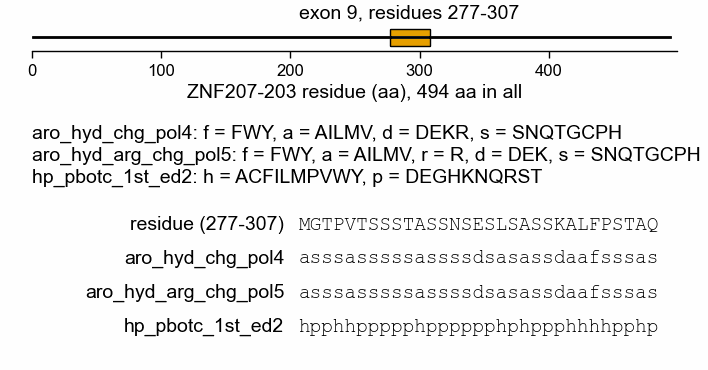

In [5]:
# ZNF207-203 as a line with exon 9 as a box, and the exon's residues in each alphabet searched.
# Axes are placed by hand: constrained layout collapses an axis that holds only text.
fig = plt.figure(figsize=(pf.ONE_COLUMN_MM * pf.MM, 50 * pf.MM), layout=None)
ax_protein = fig.add_axes([0.04, 0.80, 0.92, 0.07])
ax_seq = fig.add_axes([0.0, 0.0, 1.0, 0.62])
L = len(hero_protein)
ax_protein.plot([1, L], [0, 0], color="black", lw=1)
ax_protein.add_patch(
    plt.Rectangle(
        (HERO_FIRST, -0.5),
        HERO_LAST - HERO_FIRST + 1,
        1.0,
        facecolor=pf.OKABE_ITO["orange"],
        edgecolor="black",
        lw=0.5,
    )
)
ax_protein.text(
    (HERO_FIRST + HERO_LAST) / 2,
    0.9,
    f"exon 9, residues {HERO_FIRST}-{HERO_LAST}",
    ha="center",
    va="bottom",
)
ax_protein.set_xlim(0, L + 5)
ax_protein.set_ylim(-0.8, 0.8)
ax_protein.set_yticks([])
ax_protein.spines["left"].set_visible(False)
ax_protein.set_xlabel(f"{HERO_ISOFORM} residue (aa), {L} aa in all")

ax_seq.set_axis_off()
ax_seq.set_xlim(0, 1)
ax_seq.set_ylim(0, 1)
key_lines = [
    "aro_hyd_chg_pol4: f = FWY, a = AILMV, d = DEKR, s = SNQTGCPH",
    "aro_hyd_arg_chg_pol5: f = FWY, a = AILMV, r = R, d = DEK, s = SNQTGCPH",
    "hp_pbotc_1st_ed2: h = ACFILMPVWY, p = DEGHKNQRST",
]
for i, line in enumerate(key_lines):
    ax_seq.text(0.04, 0.95 - i * 0.09, line, ha="left", va="center")
rows = [(f"residue ({HERO_FIRST}-{HERO_LAST})", HERO_RESIDUES)] + [
    (name, cu.encode(HERO_RESIDUES, LETTER_TABLES[name]))
    for name in ["aro_hyd_chg_pol4", "aro_hyd_arg_chg_pol5", "hp_pbotc_1st_ed2"]
]
for i, (label, text) in enumerate(rows):
    y = 0.58 - i * 0.14
    ax_seq.text(0.40, y, label, ha="right", va="center")
    ax_seq.text(0.42, y, text, ha="left", va="center", family="monospace")
save_figure(fig, FIGURES / "342_znf207_exon9_residues_by_alphabet_ensembl116")